# Linear Regression — From Intuition to Implementation

A step-by-step notebook to build a deep, working understanding of **linear regression** — the foundation of most other machine learning algorithms. This continues the course sequence: *Python fundamentals → NumPy → pandas/EDA → Linear Regression*.

Every topic follows the same rhythm:
1. **Theory** — the concept and, where useful, the underlying math.
2. **Example** — a worked example you can run and study.
3. **Task** — a similar exercise for you to complete (`# TODO`).

### Dataset used
The classic **Advertising dataset** (200 markets; advertising budgets for `TV`, `radio`, `newspaper` in thousands of dollars, and resulting `sales` in thousands of units). It's the standard teaching dataset used in *An Introduction to Statistical Learning* (James, Witten, Hastie, Tibshirani) because the relationships are simple enough to build intuition, yet realistic enough to matter.

> `https://raw.githubusercontent.com/ditikrushna/Predict-Sales-Revenue-Using-Multiple-Regression-Model/master/Advertising.csv`

**Alternative source**: search "Advertising.csv ISLR" — the same 200-row dataset is mirrored in many public repositories and textbook companion sites.

### How to use this notebook
Run cells top to bottom. Read the Theory, run the Example, then attempt the Task before checking the separate solutions notebook.


## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

np.random.seed(42)
sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)

DATA_URL = "https://raw.githubusercontent.com/ditikrushna/Predict-Sales-Revenue-Using-Multiple-Regression-Model/master/Advertising.csv"

ads = pd.read_csv(DATA_URL)

print("Shape:", ads.shape)
ads.head()


Shape: (200, 4)


,TV,radio,newspaper,sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


## 1. What Is Linear Regression?

### Theory
**Linear regression** models the relationship between one or more **input variables** (also called predictors, features, or independent variables) and a **continuous output variable** (the target, or dependent variable) by fitting a **straight line** (or, with multiple inputs, a flat plane/hyperplane) through the data.

It answers questions like:
- *"If I spend more on TV advertising, how much more can I expect in sales?"*
- *"Given a house's size and location, what price should I expect?"*
- *"How does study time relate to exam score?"*

Linear regression is called a **supervised learning** algorithm because it learns from labeled examples — data where we already know both the inputs *and* the correct output — and its job is to find the best mathematical relationship between them so it can predict outputs for *new*, unseen inputs.

It's usually the first algorithm taught in machine learning because:
- It's simple enough to fully understand mathematically (no "black box").
- Many more advanced techniques (logistic regression, neural networks) build directly on its ideas.
- It's still widely used in practice for its speed and interpretability.


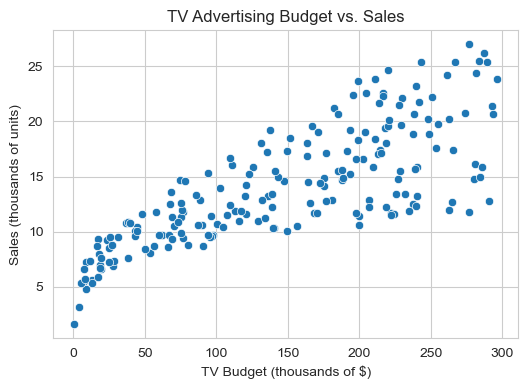

In [2]:
# EXAMPLE: visualize the relationship we're trying to model
plt.figure(figsize=(6, 4))
sns.scatterplot(data=ads, x='TV', y='sales')
plt.title('TV Advertising Budget vs. Sales')
plt.xlabel('TV Budget (thousands of $)')
plt.ylabel('Sales (thousands of units)')
plt.show()


### Task 1
Create a scatter plot of `Radio` budget vs. `Sales`, and a separate one for `Newspaper` budget vs. `Sales`. Just by looking at the three scatter plots (TV, Radio, Newspaper), which advertising channel appears to have the **strongest** linear relationship with `Sales`, and which appears **weakest**? Answer in a `print()` statement.

In [3]:
ads.columns

Index(['TV', 'radio', 'newspaper', 'sales'], dtype='object')

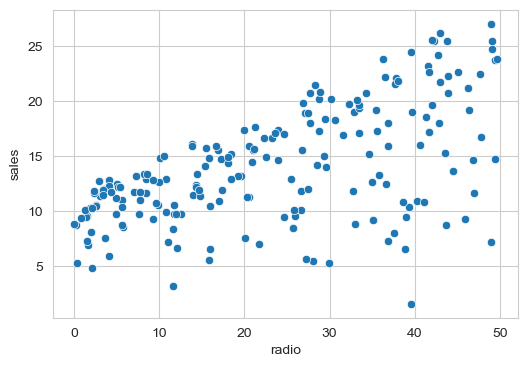

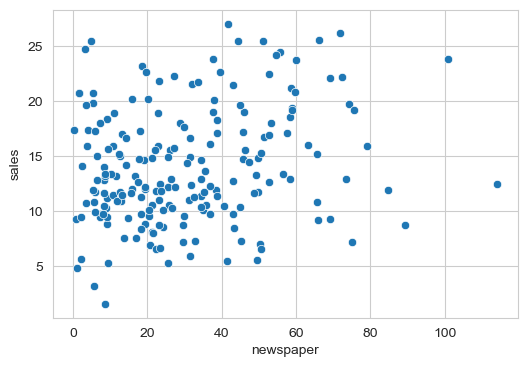

Radio has much better linear relationship compared to Newspaper to Sales.


In [6]:
# TODO: scatter plot Radio vs Sales
plt.figure(figsize=(6, 4))
sns.scatterplot(data=ads, x='radio', y='sales')
plt.show()
# TODO: scatter plot Newspaper vs Sales
plt.figure(figsize=(6, 4))
sns.scatterplot(data=ads, x='newspaper', y='sales')
plt.show()
# TODO: print() your observation about strongest/weakest relationship
print("Radio has much better linear relationship compared to Newspaper to Sales.")

## 2. Simple Linear Regression: The Model

### Theory
**Simple linear regression** uses exactly **one** input variable $x$ to predict an output $y$. The model assumes:

$$\hat{y} = \beta_0 + \beta_1 x$$

Where:
- $\hat{y}$ ("y-hat") is the **predicted** value of $y$
- $\beta_0$ is the **intercept** — the predicted value of $y$ when $x = 0$
- $\beta_1$ is the **slope** (coefficient) — how much $\hat{y}$ changes for every one-unit increase in $x$

**"Fitting" the model** means finding the specific values of $\beta_0$ and $\beta_1$ that make the line best match the observed data points. No line will pass through every point exactly — real data has noise/variation, so each actual observation $y_i$ differs from the line's prediction $\hat{y}_i$ by a **residual** (error): $e_i = y_i - \hat{y}_i$.


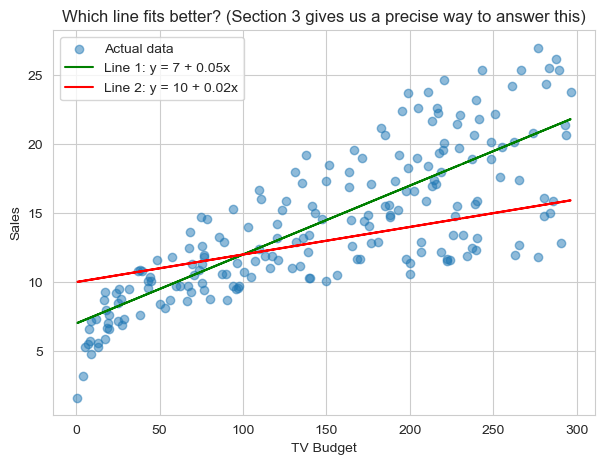

In [8]:
x = ads['TV'].values
y = ads['sales'].values

line1 = 7 + 0.05 * x     # a guess: intercept=7, slope=0.05
line2 = 10 + 0.02 * x    # another guess: intercept=10, slope=0.02

plt.figure(figsize=(7, 5))
plt.scatter(x, y, alpha=0.5, label='Actual data')
plt.plot(x, line1, color='green', label='Line 1: y = 7 + 0.05x')
plt.plot(x, line2, color='red', label='Line 2: y = 10 + 0.02x')
plt.xlabel('TV Budget')
plt.ylabel('Sales')
plt.legend()
plt.title('Which line fits better? (Section 3 gives us a precise way to answer this)')
plt.show()

### Task 2
Using the formula $\hat{y} = \beta_0 + \beta_1 x$, manually compute the **predicted sales** for a TV budget of `x = 150` using two different guesses:
1. $\beta_0 = 7,\ \beta_1 = 0.05$
2. $\beta_0 = 10,\ \beta_1 = 0.02$

Print both predictions.

In [12]:
# TODO: predicted sales at TV=150 for both guesses of (beta0, beta1)
b0, b1, x = 7, 0.05, 150
pred_sales_1 = b0 + b1*x

print(f"Sales:{pred_sales_1} when beta_0 = 7 and beta_1 = 0.05")

b0, b1, x = 10, 0.02, 150
pred_sales_2 = b0 + b1*x

print(f"Sales:{pred_sales_2} when beta_0 = 10 and beta_1 = 0.02")


Sales:14.5 when beta_0 = 7 and beta_1 = 0.05
Sales:13.0 when beta_0 = 10 and beta_1 = 0.02


## 3. The Cost Function (Mean Squared Error)

### Theory
To decide which line is "best," we need a way to **measure how wrong** a line's predictions are, across *all* data points at once. The most common choice for linear regression is the **Mean Squared Error (MSE)**:

$$\text{MSE} = \frac{1}{n}\sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$

- We **square** each residual so that positive and negative errors don't cancel out, and so that larger errors are penalized disproportionately more than small ones.
- We take the **mean** so the metric doesn't just grow because you have more data points.
- This MSE, as a function of $\beta_0$ and $\beta_1$, is called the **cost function** (or **loss function**) — "fitting" a model literally means searching for the $\beta_0, \beta_1$ that **minimize** this cost function. This is why linear regression is sometimes called an **optimization problem**.


In [13]:
# EXAMPLE: compute the MSE for our two candidate lines from Section 2
def compute_mse(y_actual, y_predicted):
    return np.mean((y_actual - y_predicted) ** 2)

mse_line1 = compute_mse(y, line1)
mse_line2 = compute_mse(y, line2)

print(f"MSE for Line 1 (7 + 0.05x): {mse_line1:.2f}")
print(f"MSE for Line 2 (10 + 0.02x): {mse_line2:.2f}")
print("Line 1 is better." if mse_line1 < mse_line2 else "Line 2 is better.")


MSE for Line 1 (7 + 0.05x): 10.67
MSE for Line 2 (10 + 0.02x): 17.24
Line 1 is better.


### Task 3
Write your own function `mse(y_actual, y_predicted)` (don't just reuse the example's — write it yourself for practice) and use it to evaluate a **third** candidate line: $\beta_0 = 8,\ \beta_1 = 0.04$. Is it better or worse than Line 1 and Line 2 above?

In [19]:
# TODO: define your own mse(y_actual, y_predicted) function
def mse(y_act, y_pred):
    return np.mean((y_act - y_pred) ** 2)

# TODO: evaluate line3 = 8 + 0.04x using your mse function, compare to Line 1 and Line 2
line3 = 8 + 0.04*x
mse_line3 = mse(y, line3)

print(f"MSE for Line 3 (8 + 0.04x): {mse_line3:.2f}")

MSE for Line 3 (8 + 0.04x): 27.09


## 5. Finding the Best Fit: Gradient Descent

### Theory
The closed-form OLS solution above works cleanly for simple linear regression, but for more complex models (many features, or other algorithms like neural networks), a direct formula isn't always available or efficient. **Gradient descent** is an iterative, general-purpose optimization algorithm that works in those cases too — it's worth understanding even here, on a problem simple enough to visualize clearly.

The idea:
1. Start with random guesses for $\beta_0, \beta_1$.
2. Compute the **gradient** (slope) of the cost function with respect to each parameter — this tells us which direction increases the cost.
3. Update each parameter by taking a small step in the **opposite** direction (downhill), scaled by a **learning rate** $\alpha$.
4. Repeat until the cost stops improving much.

$$\beta_0 := \beta_0 - \alpha \frac{\partial \text{MSE}}{\partial \beta_0} \qquad \qquad \beta_1 := \beta_1 - \alpha \frac{\partial \text{MSE}}{\partial \beta_1}$$

Picking the **learning rate** matters: too small and training is painfully slow; too large and the algorithm can overshoot and fail to converge (or even diverge).


Final beta0 = 14.0225, beta1 = 4.0710
Final MSE = 10.5127


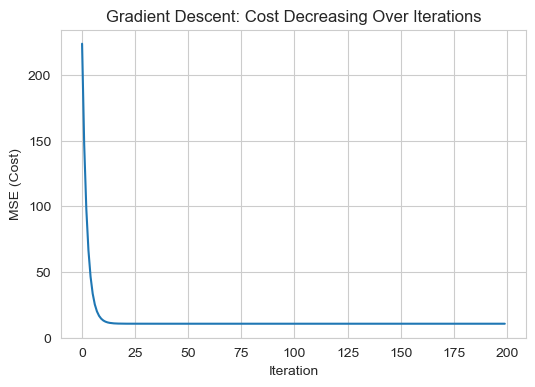

In [22]:
# EXAMPLE: gradient descent from scratch for TV -> Sales
# Feature scaling helps gradient descent converge much faster and more reliably
import numpy as np
import matplotlib.pyplot as plt

# TV should be the entire column, not a single number
x = ads['TV'].to_numpy()
y = ads['sales'].to_numpy()

# Feature scaling
x_scaled = (x - x.mean()) / x.std()

beta0, beta1 = 0.0, 0.0
learning_rate = 0.1
n_iterations = 200
n = len(x_scaled)
cost_history = []

for iteration in range(n_iterations):
    y_pred = beta0 + beta1 * x_scaled
    error = y_pred - y

    grad_beta0 = (2 / n) * np.sum(error)
    grad_beta1 = (2 / n) * np.sum(error * x_scaled)

    beta0 -= learning_rate * grad_beta0
    beta1 -= learning_rate * grad_beta1

    cost_history.append(np.mean(error ** 2))

print(f"Final beta0 = {beta0:.4f}, beta1 = {beta1:.4f}")
print(f"Final MSE = {cost_history[-1]:.4f}")

plt.figure(figsize=(6, 4))
plt.plot(cost_history)
plt.xlabel('Iteration')
plt.ylabel('MSE (Cost)')
plt.title('Gradient Descent: Cost Decreasing Over Iterations')
plt.show()


### Task 5
1. Re-run gradient descent (on the same scaled TV data) with a **much smaller** learning rate, e.g. `0.001`, for `200` iterations. Plot the cost history — what do you observe compared to the example above?
2. Try a **much larger** learning rate, e.g. `1.5`. What happens to the cost history now?
3. In a `print()` statement, briefly summarize what these two experiments taught you about choosing a learning rate.

Final beta0 = 4.6267, beta1 = 1.3432
Final MSE = 106.6185


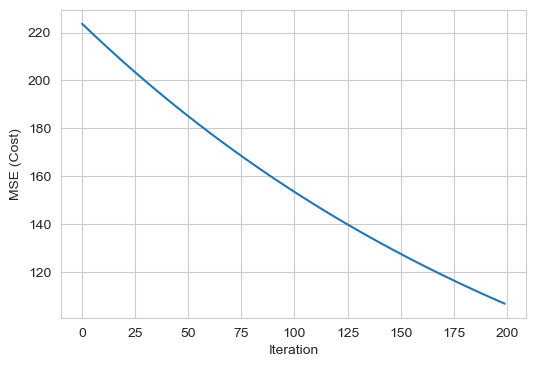

Final beta0 = -22533288725621718199403417144853297458969572242746998349889536.0000, beta1 = -6541854613679248238993160011749241996163345113492408919654400.0000
Final MSE = 137636240644686865882472110451890759190157927471700899448688819853281152221078535905779374935610488512840457046428085125120.0000


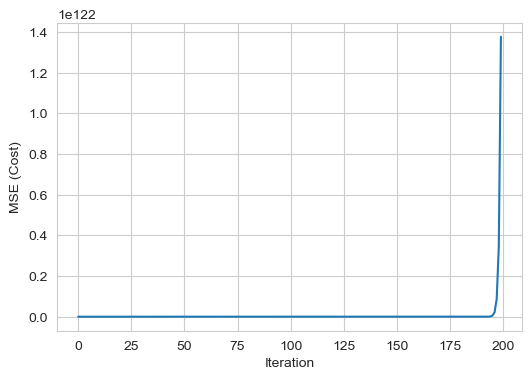

For learning rate =0.001 the mean squared error is gradually decreasing like how a model should should learn, but when lr=1.5, the error is increasing which is a bad configuration of a model.


In [35]:
# TODO: gradient descent with a small learning rate (e.g. 0.001), plot cost history
beta0, beta1 = 0.0, 0.0
learning_rate = 0.001
n_iterations = 200
n = len(x_scaled)
cost_history = []

for iteration in range(n_iterations):
    y_pred = beta0 + beta1 * x_scaled
    error = y_pred - y

    grad_beta0 = (2 / n) * np.sum(error)
    grad_beta1 = (2 / n) * np.sum(error * x_scaled)

    beta0 -= learning_rate * grad_beta0
    beta1 -= learning_rate * grad_beta1

    cost_history.append(np.mean(error ** 2))

print(f"Final beta0 = {beta0:.4f}, beta1 = {beta1:.4f}")
print(f"Final MSE = {cost_history[-1]:.4f}")

plt.figure(figsize=(6, 4))
plt.plot(cost_history)
plt.xlabel('Iteration')
plt.ylabel('MSE (Cost)')
plt.show()

# TODO: gradient descent with a large learning rate (e.g. 1.5), plot cost history
beta0, beta1 = 0.0, 0.0
learning_rate = 1.5
n_iterations = 200
n = len(x_scaled)
cost_history = []

for iteration in range(n_iterations):
    y_pred = beta0 + beta1 * x_scaled
    error = y_pred - y

    grad_beta0 = (2 / n) * np.sum(error)
    grad_beta1 = (2 / n) * np.sum(error * x_scaled)

    beta0 -= learning_rate * grad_beta0
    beta1 -= learning_rate * grad_beta1

    cost_history.append(np.mean(error ** 2))

print(f"Final beta0 = {beta0:.4f}, beta1 = {beta1:.4f}")
print(f"Final MSE = {cost_history[-1]:.4f}")

plt.figure(figsize=(6, 4))
plt.plot(cost_history)
plt.xlabel('Iteration')
plt.ylabel('MSE (Cost)')
plt.show()
# TODO: print() your summary about learning rate choice
print("For learning rate =0.001 the mean squared error is gradually decreasing like how a model should should learn, but when lr=1.5, the error is increasing which is a bad configuration of a model.")

## 6. Train/Test Split and Generalization

### Theory
So far we've evaluated models on the **same** data they were trained on — but a model's real value is in predicting **new, unseen** data well. Evaluating only on training data risks **overfitting**: getting a model that has essentially "memorized" the training set but performs poorly on new data.

The standard practice is to **split the data** before training:
- **Training set** (typically 70-80%) — used to fit the model.
- **Test set** (remaining 20-30%) — held out, used only to evaluate the final model's performance on data it has never seen.

`train_test_split()` from `sklearn.model_selection` does this randomly (use `random_state` for reproducibility).


In [36]:
import numpy as np
import pandas as pd

def gradient_descent_multi(X, y, learning_rate=0.01, epochs=1000):
    """
    Performs batch gradient descent for multiple linear regression.

    Parameters:
    - X: feature matrix (pandas DataFrame or 2D numpy array)
    - y: target variable (pandas Series or 1D numpy array)
    - learning_rate (float): step size for parameter updates (alpha)
    - epochs (int): number of iterations through the dataset

    Returns:
    - weights: learned coefficients for each feature
    - bias: learned intercept
    - loss_history: list of MSE loss values per epoch
    """
    # Ensure inputs are numpy arrays
    X_mat = np.array(X, dtype=np.float64)
    y_vec = np.array(y, dtype=np.float64).reshape(-1, 1)

    num_samples, num_features = X_mat.shape

    # 1. Initialize parameters (weights and bias) to zeros
    weights = np.zeros((num_features, 1))
    bias = 0.0

    loss_history = []

    for epoch in range(epochs):
        # 2. Forward pass: Calculate predictions y_hat = X * w + b
        y_pred = np.dot(X_mat, weights) + bias

        # 3. Calculate error
        error = y_pred - y_vec

        # 4. Compute Loss (Mean Squared Error)
        mse_loss = np.mean(error ** 2)
        loss_history.append(mse_loss)

        # 5. Compute Gradients
        # dL/dw = (2/n) * X^T * (y_pred - y)
        dw = (2 / num_samples) * np.dot(X_mat.T, error)
        # dL/db = (2/n) * sum(y_pred - y)
        db = (2 / num_samples) * np.sum(error)

        # 6. Update Parameters
        weights -= learning_rate * dw
        bias -= learning_rate * db

        # Print progress every 10% of total epochs
        if (epoch + 1) % max(1, epochs // 10) == 0:
            print(f"Epoch {epoch+1}/{epochs} - Loss (MSE): {mse_loss:.4f}")

    return weights.flatten(), bias, loss_history

In [37]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Prepare Features & Target
X_multi = ads[['TV', 'radio', 'newspaper']]
y = ads['sales']

# 2. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X_multi, y, test_size=0.2, random_state=42
)

print("Training set size:", X_train.shape)
print("Test set size:    ", X_test.shape)

# 3. Scale Features (Fit on train ONLY to prevent data leakage)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Fit Custom Gradient Descent Model (ONLY on training set)
learning_rate = 0.05
epochs = 500

weights, bias, loss_history = gradient_descent_multi(
    X_train_scaled, y_train, learning_rate=learning_rate, epochs=epochs
)



Training set size: (160, 3)
Test set size:     (40, 3)
Epoch 50/500 - Loss (MSE): 2.7158
Epoch 100/500 - Loss (MSE): 2.7051
Epoch 150/500 - Loss (MSE): 2.7051
Epoch 200/500 - Loss (MSE): 2.7051
Epoch 250/500 - Loss (MSE): 2.7051
Epoch 300/500 - Loss (MSE): 2.7051
Epoch 350/500 - Loss (MSE): 2.7051
Epoch 400/500 - Loss (MSE): 2.7051
Epoch 450/500 - Loss (MSE): 2.7051
Epoch 500/500 - Loss (MSE): 2.7051


## 7. Model Evaluation Metrics

### Theory
Once a model is fit, we need standard ways to report **how good** its predictions are:

- **MAE (Mean Absolute Error)**: $\frac{1}{n}\sum |y_i - \hat{y}_i|$ — average absolute error, in the same units as $y$. Easy to interpret, less sensitive to outliers than MSE.
- **MSE (Mean Squared Error)**: as introduced in Section 3 — penalizes large errors more heavily.
- **RMSE (Root Mean Squared Error)**: $\sqrt{\text{MSE}}$ — brings the error back into the same units as $y$ (unlike MSE, which is in *squared* units), while still penalizing large errors.
- **R² (Coefficient of Determination)**: the proportion of variance in $y$ that the model explains, ranging (typically) from 0 to 1 — an R² of `0.85` means the model explains 85% of the variation in sales. R² close to 0 means the model is barely better than just predicting the average $y$ for everything; R² of 1 means perfect predictions.

`scikit-learn` provides all of these in `sklearn.metrics`.


In [38]:
# 5. Generate Predictions for Train and Test sets
y_train_pred = np.dot(X_train_scaled, weights) + bias
y_test_pred = np.dot(X_test_scaled, weights) + bias

# 6. Calculate Evaluation Metrics
train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)

mae = mean_absolute_error(y_test, y_test_pred)
mse = mean_squared_error(y_test, y_test_pred)
rmse = np.sqrt(mse)

# 7. Print Results
print("\n--- Gradient Descent Evaluation ---")
print(f"R^2 on training set: {train_r2:.4f}")
print(f"R^2 on test set:     {test_r2:.4f}")
print(f"Test MAE:            {mae:.3f}")
print(f"Test MSE:            {mse:.3f}")
print(f"Test RMSE:           {rmse:.3f}")
print("\nA test R^2 close to the training R^2 suggests the model generalizes well.")


--- Gradient Descent Evaluation ---
R^2 on training set: 0.8957
R^2 on test set:     0.8994
Test MAE:            1.461
Test MSE:            3.174
Test RMSE:           1.782

A test R^2 close to the training R^2 suggests the model generalizes well.


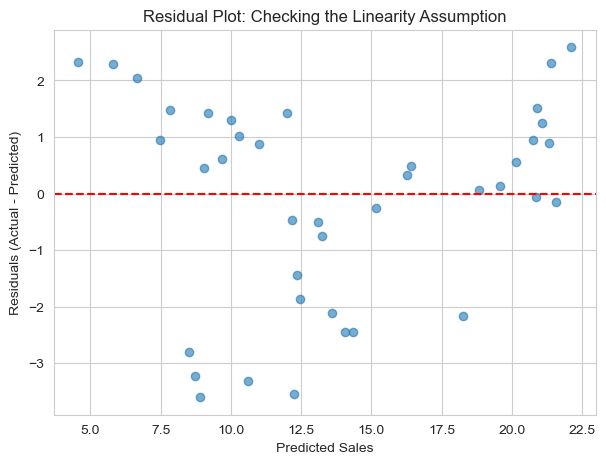

In [39]:
residuals = y_test - y_test_pred

plt.figure(figsize=(7, 5))
plt.scatter(y_test_pred, residuals, alpha=0.6)
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel('Predicted Sales')
plt.ylabel('Residuals (Actual - Predicted)')
plt.title('Residual Plot: Checking the Linearity Assumption')
plt.show()

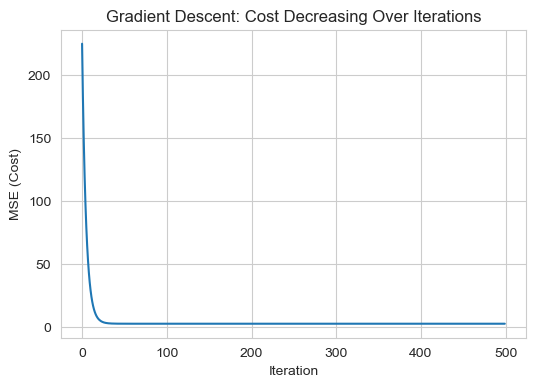

In [40]:
plt.figure(figsize=(6, 4))
plt.plot(loss_history)
plt.xlabel('Iteration')
plt.ylabel('MSE (Cost)')
plt.title('Gradient Descent: Cost Decreasing Over Iterations')
plt.show()

**bold text**### Task 7
1. Repeat the train/test split, but with `test_size=0.3` and `random_state=1`.
2. Fit a `LinearRegression` model using `TV` and `Radio` only, on the training data.
3. Print the R² on both the training set and the test set, and comment (via `print()`) on whether the model seems to generalize well.

In [41]:
# TODO: train/test split with test_size=0.3, random_state=1
X = ads[['TV', 'radio']]
y = ads['sales']

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=1
)
# TODO: fit LinearRegression on TV and Radio, using training data only
model = LinearRegression()
model.fit(X_train, y_train)

# TODO: print R^2 on train and test sets, and comment on generalization
train_r2 = model.score(X_train, y_train)
test_r2 = model.score(X_test, y_test)

print(f"Train R²: {train_r2:.4f}")
print(f"Test R²: {test_r2:.4f}")


Train R²: 0.8850
Test R²: 0.9230
